# CREDIT RISK MODELLING

1. Setting the Background

The most pressing questions for banks are how efficiently can we guage the risk profile of our customers and how can we use this information to decide on the required liquidity while still maintaining our regulatory obligations.

With the constantly changing customer portfolio and the ever increasing customer base a more robust non-hardcoded approach is neccessary to achieve these antagonistic goals.

Thus comes the idea of using machine learning to develop a behavioural scorecard to pull data from both internal sources, customer transactions and their demographic data, to predict the probability of default.

In this notebook we are going to explore the data cleaning and transformation as well as machine learing modelling in predicting probability of default. We can then use these results to develop a credit rating.

We will eplore the following concepts in the notebook
1. Data cleaning - Struucturing the data for modelling
2. What to do with missing values
3. How to deal with class imbalance and the implications.


In [ ]:
# General Libraries

import warnings
warnings.filterwarnings('ignore')

# Data Explotation libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt #Visualization
import seaborn as sns #Advanced Visualization
%matplotlib inline

# Data modelling libraries
from sklearn.impute import SimpleImputer
from collections import Counter
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report, confusion_matrix
import itertools
from sklearn.metrics import f1_score

: 

In [ ]:
#Loading data
Loan = pd.read_csv("raw-data.csv")
Loan.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32
0,1,0,0,24.0,0.0,2432.0,46500.0,24.0,1385.0,SC,...,NaN,NaN,46500.0,NaN,NaN,0,0,0,TIER 1,0
1,2,0,1,24.0,1.0,1495.0,28168.0,24.0,2496.0,MO,...,NaN,NaN,28168.0,NaN,NaN,0,0,0,TIER 1,0
2,3,0,0,26.0,0.0,1707.0,38900.0,30.0,1346.0,SC,...,NaN,105000.0,38900.0,34.0,31.0,31,31,16,TIER 1,0
3,4,0,0,24.0,0.0,2128.0,42900.0,24.0,1375.0,SC,...,NaN,NaN,42900.0,NaN,NaN,0,0,0,TIER 1,0
4,5,0,0,27.0,0.0,1824.0,40900.0,30.0,4140.0,MC,...,NaN,NaN,40900.0,NaN,NaN,0,0,0,TIER 1,0


In [11]:
#Renaming columns in the dataset with their correct names
Loan_renamed2 = Loan.rename(columns={'V1': 'Customer ID',
'V2': 'Customer has bounced in first EMI',
'V3': 'No of times bounced 12 months',
'V4': 'Maximum MOB',
'V5': 'No of times bounced while repaying the loan',
'V6': 'EMI',
'V7': 'Loan Amount',
'V8': 'Tenure',
'V9': 'Dealer codes from where customer has purchased the Two wheeler',
'V10': 'Product code of Two wheeler',
'V11': 'No of advance EMI paid',
'V12': 'Rate of interest',
'V13': 'Gender',
'V14': 'Employment type',
'V15': 'Resident type of customer',
'V16': 'Date of birth',
'V17': 'Customer age when loanwas taken',
'V18': 'No of loans',
'V19': 'No of secured loans',
'V20': 'No of unsecured loans',
'V21': 'Max amount sanctioned in the Live loans',
'V22': 'No of new loans in last 3 months',
'V23': 'Total sanctioned amount in the secured Loans which are Live',
'V24': 'Total sanctioned amount in the unsecured Loans which are Live',
'V25': 'Maximum amount sanctioned for any Two wheeler loan',
'V26': 'Time since last Personal loan taken (in months)',
'V27': 'Time since first consumer durables loan taken (in months)',
'V28': 'No of times 30 days past due in last 6 months',
'V29': 'No of times 60 days past due in last 6 months',
'V30': 'No of times 90 days past due in last 3 months',
'V31': 'Tier',
'V32': 'Target variable'})
Loan_renamed2.head(2)

,Customer ID,Customer has bounced in first EMI,No of times bounced 12 months,Maximum MOB,No of times bounced while repaying the loan,EMI,Loan Amount,Tenure,Dealer codes from where customer has purchased the Two wheeler,Product code of Two wheeler,...,Total sanctioned amount in the secured Loans which are Live,Total sanctioned amount in the unsecured Loans which are Live,Maximum amount sanctioned for any Two wheeler loan,Time since last Personal loan taken (in months),Time since first consumer durables loan taken (in months),No of times 30 days past due in last 6 months,No of times 60 days past due in last 6 months,No of times 90 days past due in last 3 months,Tier,Target variable
0,1,0,0,24.0,0.0,2432.0,46500.0,24.0,1385.0,SC,...,NaN,NaN,46500.0,NaN,NaN,0,0,0,TIER 1,0
1,2,0,1,24.0,1.0,1495.0,28168.0,24.0,2496.0,MO,...,NaN,NaN,28168.0,NaN,NaN,0,0,0,TIER 1,0


# 3. Basic EDA and Data Cleaning

In [12]:
Loan_renamed2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119528 entries, 0 to 119527
Data columns (total 32 columns):
 #   Column                                                          Non-Null Count   Dtype  
---  ------                                                          --------------   -----  
 0   Customer ID                                                     119528 non-null  int64  
 1   Customer has bounced in first EMI                               119528 non-null  int64  
 2   No of times bounced 12 months                                   119528 non-null  int64  
 3   Maximum MOB                                                     85048 non-null   float64
 4   No of times bounced while repaying the loan                     85048 non-null   float64
 5   EMI                                                             85048 non-null   float64
 6   Loan Amount                                                     85048 non-null   float64
 7   Tenure                                

In [ ]:
#Removing irrelevant columns
# #irrelevant_columns = ['Time since first consumer durables loan taken (in months)','Time since last Personal loan taken (in months)']
# Loan_renamed.drop(['Time since first consumer durables loan taken (in months)','Time since last Personal loan taken (in months)'], axis = 1, inplace = True)
# Loan_renamed.shape

### Missing Values Analysis

In [14]:
missing = Loan_renamed2.isnull().mean() * 100
missing.sort_values(ascending=False)

Time since last Personal loan taken (in months)                   88.763302
Total sanctioned amount in the unsecured Loans which are Live     84.080717
Total sanctioned amount in the secured Loans which are Live       83.869052
Time since first consumer durables loan taken (in months)         82.905261
Max amount sanctioned in the Live loans                           69.357807
Resident type of customer                                         29.613982
EMI                                                               28.846797
Maximum MOB                                                       28.846797
Rate of interest                                                  28.846797
Gender                                                            28.846797
Employment type                                                   28.846797
Loan Amount                                                       28.846797
Tenure                                                            28.846797
No of advanc

- columns like (time since last loan was taken, total sunctioned amounts in unsecured and secured loans, time since first consumer loans durable taken, maximum amount of sunctioned in live loans) will be droped since they have high missingness.

- Columns like Gender, Loan amount , age and the rest with missingness will be droped; Values missing completely at random.  

In [16]:
# missing values treatment
Loan_renamed2.dropna(axis=0,how='any',subset=['Loan Amount','Gender'], inplace=True)

In [17]:
# drop columns with high missingness
high_missing_cols = [
    'Time since last Personal loan taken (in months)',
    'Total sanctioned amount in the unsecured Loans which are Live',
    'Total sanctioned amount in the secured Loans which are Live',
    'Time since first consumer durables loan taken (in months)'
]

Loan_cleaned = Loan_renamed2.drop(columns=high_missing_cols)

In [42]:
#Missingness in categorical columns fill with unknown
categorical_cols = [
    'Gender','Employment type',
    'Resident type of customer','Product code of Two wheeler'
]

for col in categorical_cols:
    mode_value = Loan_cleaned[col].mode()[0]
    Loan_cleaned[col].fillna(mode_value, inplace=True)

In [20]:
Loan_cleaned.shape

(85048, 28)

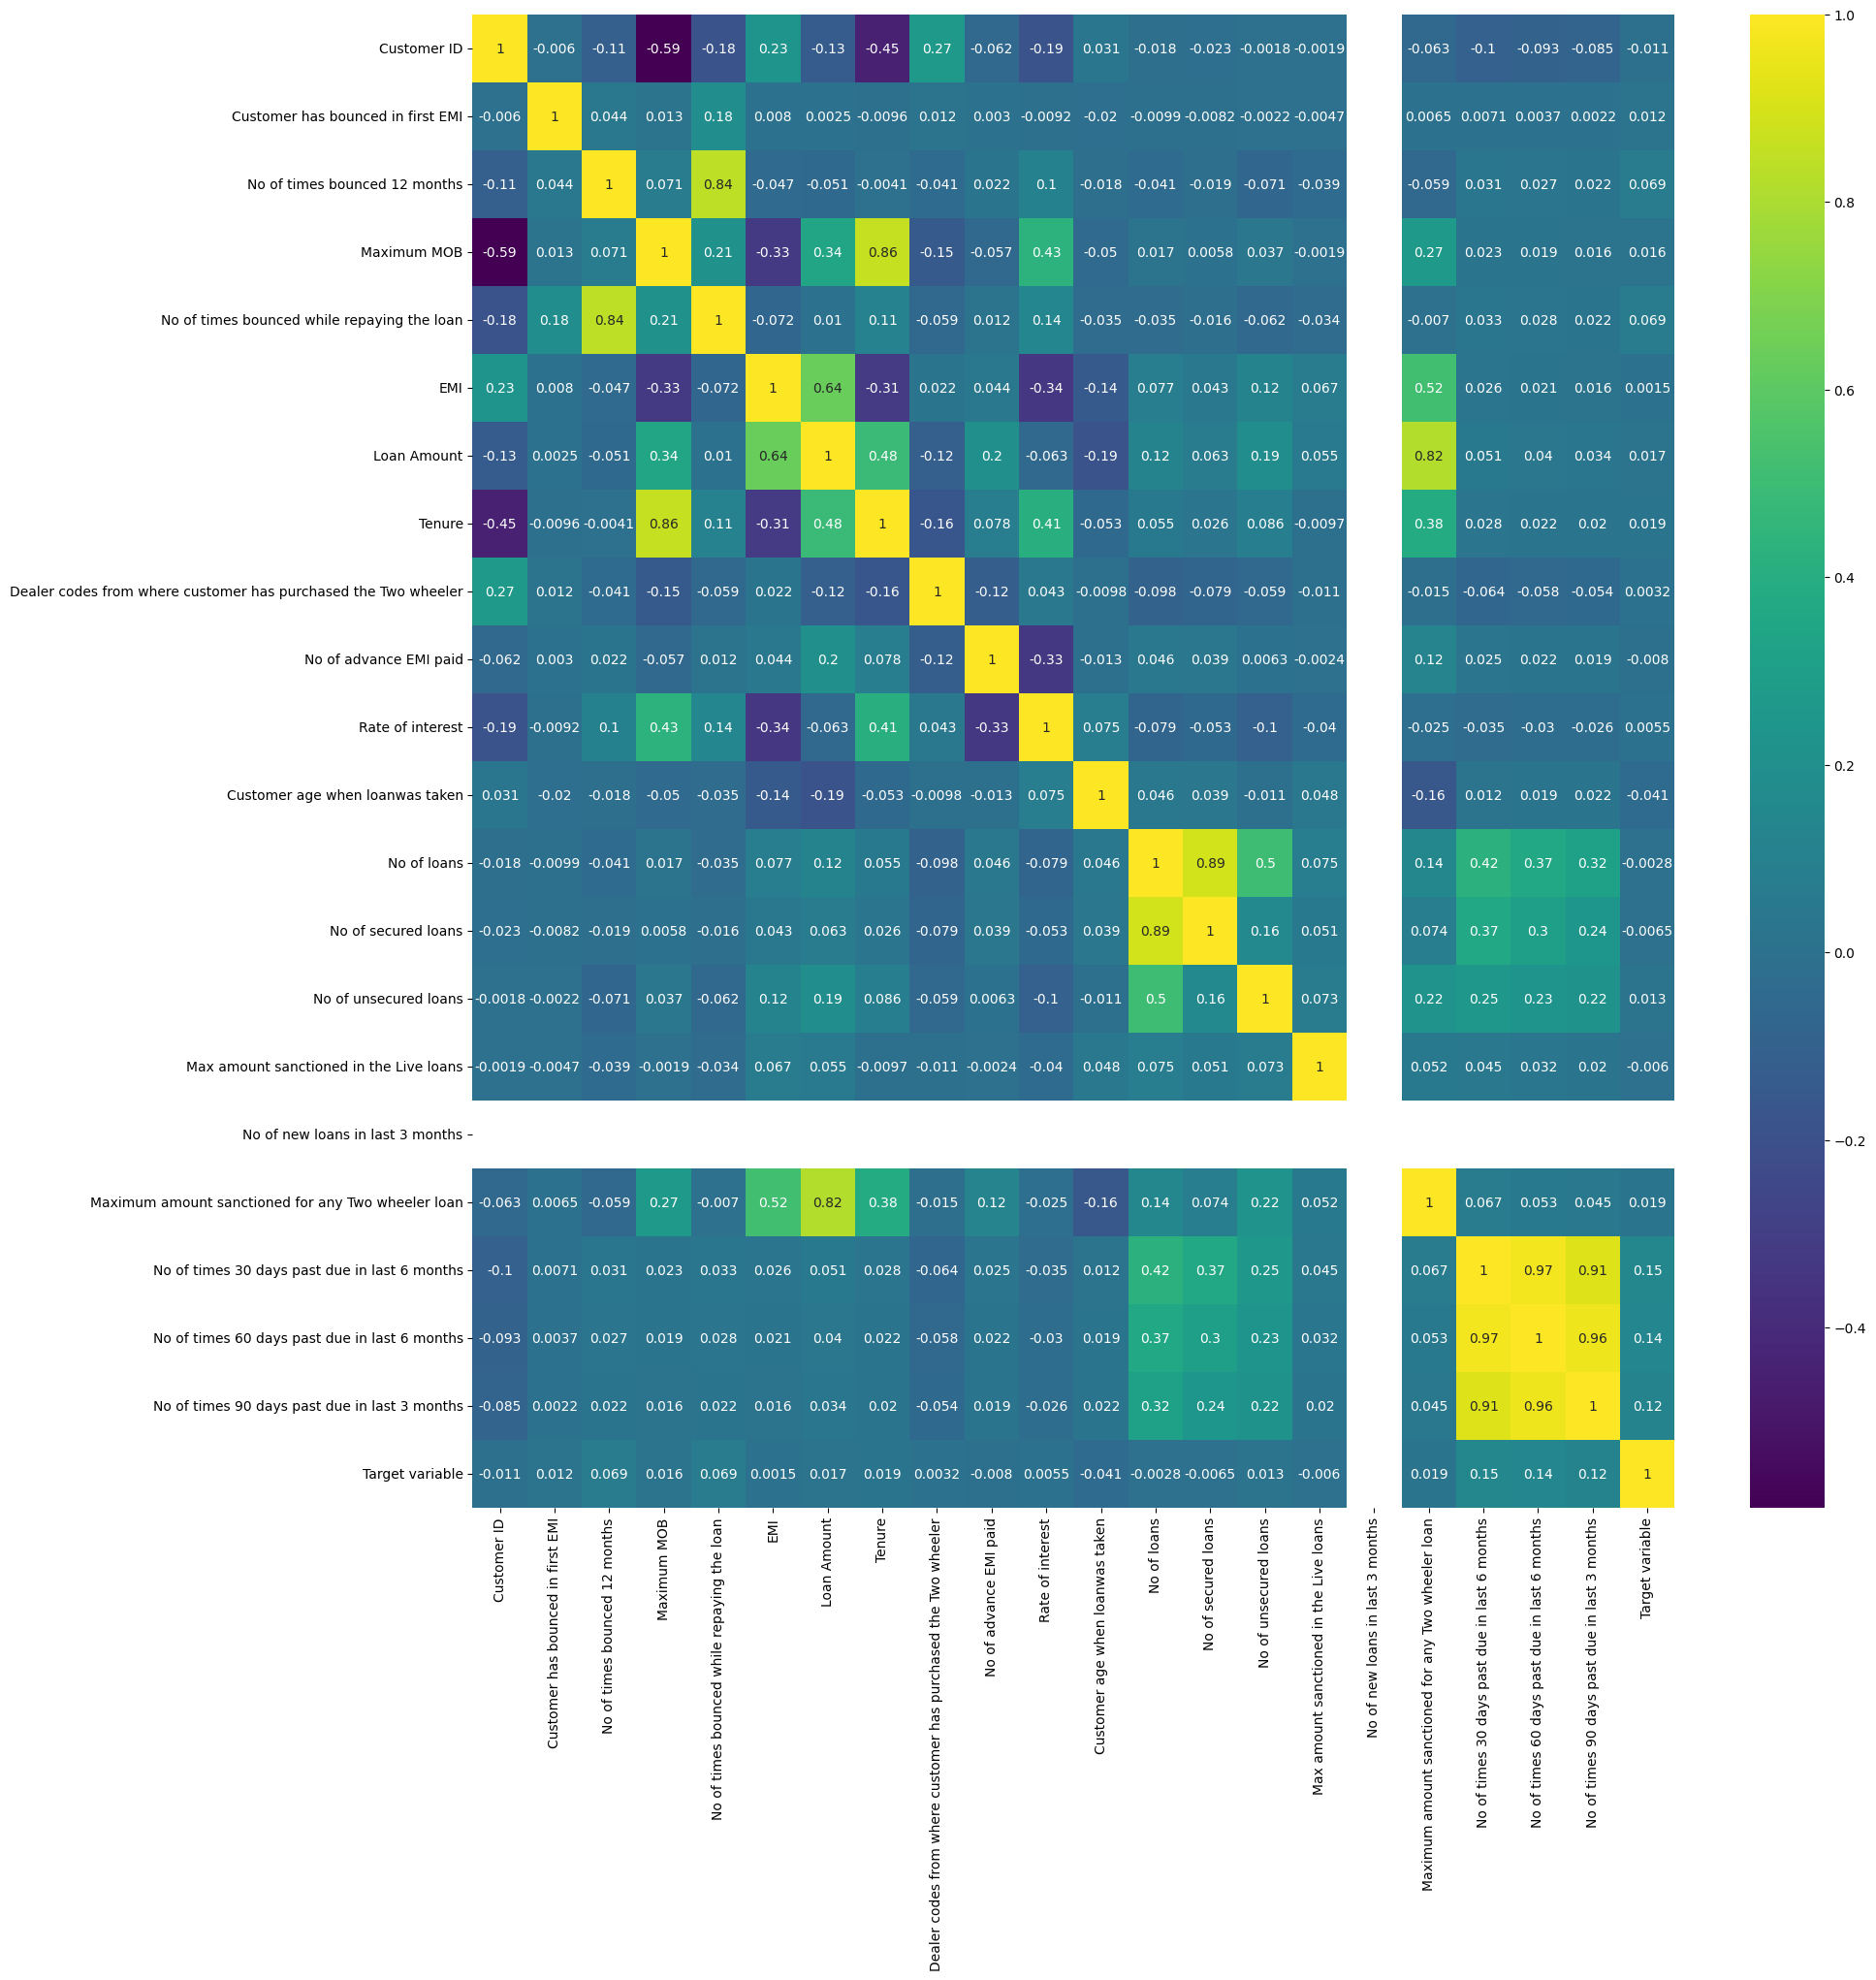

In [21]:
#correlation matrix
corrmat = Loan_cleaned.select_dtypes(include='number').corr()
top_corr_features = corrmat.index
plt.figure(figsize=(20,20))
g=sns.heatmap(Loan_cleaned[top_corr_features].corr(),annot=True,cmap="viridis")

In [25]:
# Target ariable analysis
Loan_cleaned['Target variable'].value_counts(normalize=True)

Target variable
0    0.978201
1    0.021799
Name: proportion, dtype: float64

- Above dataset is imbalanced since the target variable class 0 is 97% (good customers ) while default ones are only 2.19%
- The target variable is highly imbalanced, with defaulters representing approximately 2% of the total population. This reflects real-world credit portfolios where default events are rare but financially significant. Due to this imbalance, accuracy alone is not a reliable evaluation metric, as a naive model predicting all observations as non-defaulters would still achieve high accuracy.

Target variable
0    83194
1     1854
Name: count, dtype: int64


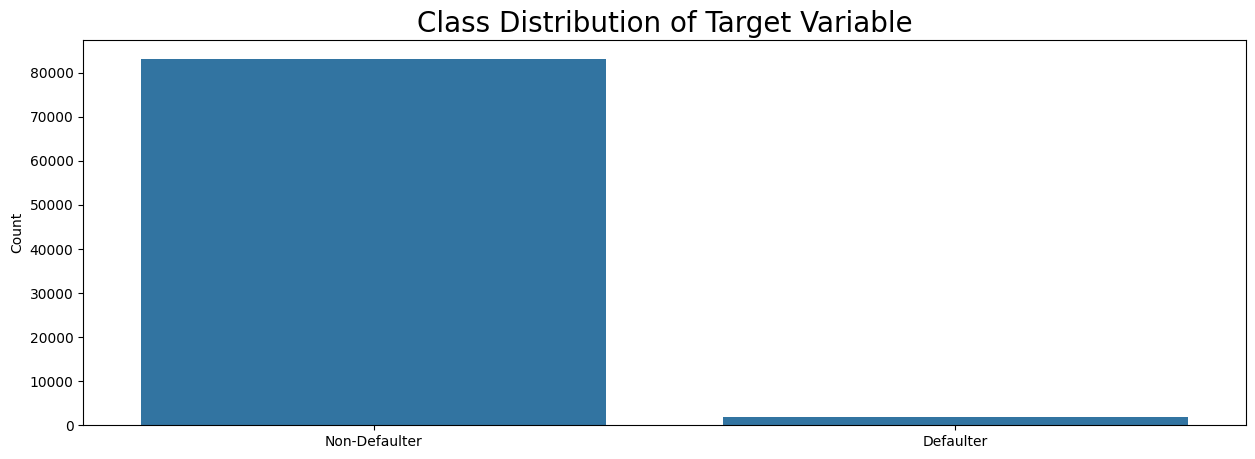

In [ ]:
# # Getting the number of positive and negative examples.
plt.figure(figsize=(15,5))
sns.countplot(x='Target variable', data=Loan_cleaned)
plt.xticks((0, 1), ["Non-Defaulter", "Defaulter"])
plt.xlabel("")
plt.ylabel("Count")
plt.title("Class Distribution of Target Variable", y=1, fontsize=20)

print(Loan_cleaned['Target variable'].value_counts())

- The imbalance above  Will be explained in the next section how to handle all of them after giving an overview of ensemble methods


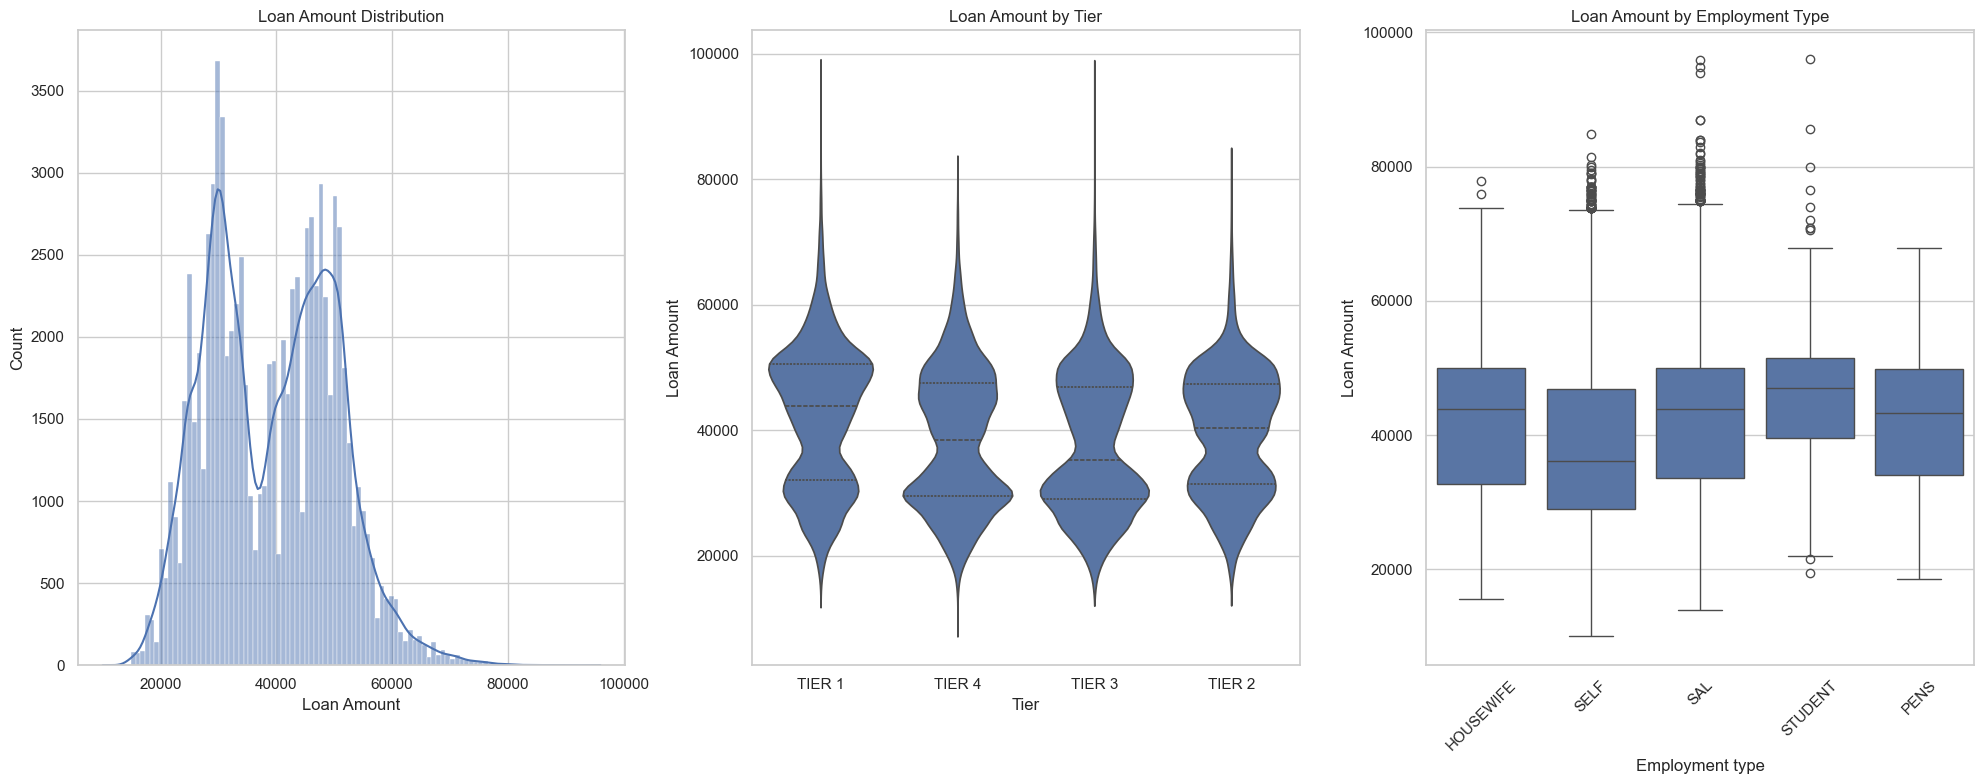

In [26]:
sns.set(style="whitegrid")

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(20,8))

# 1. Distribution plot
ax[0].set_title("Loan Amount Distribution")
sns.histplot(
    Loan_cleaned['Loan Amount'],
    kde=True,
    ax=ax[0]
)

# 2. Violin plot by Tier
ax[1].set_title("Loan Amount by Tier")
sns.violinplot(
    data=Loan_cleaned,
    x='Tier',
    y='Loan Amount',
    ax=ax[1],
    inner="quartile"
)

# 3. Box plot by Employment Type
ax[2].set_title("Loan Amount by Employment Type")
sns.boxplot(
    data=Loan_cleaned,
    x='Employment type',
    y='Loan Amount',
    ax=ax[2]
)
ax[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

- Loan amount distribution is right skewed
- Loan amounts per tier vary with most members in Tier1 taking loan amounts are between 3000 and 50000 with an average of 450000 ; Tier4 most loan amounts range between 28000 and 43000 with an average of 38000, while Tier3 most  borrow loans amounts range from 27000 and 42000 with an average of 37000
- High amounts are borrowed in tier1 and tier2
- Most loans are taken by students 


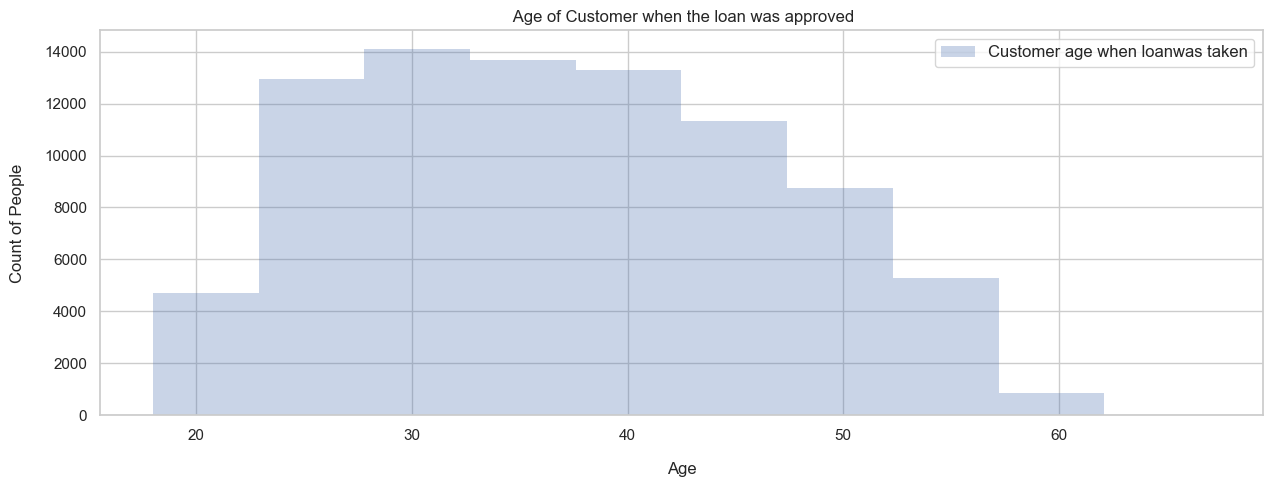

In [27]:
##Age- age at which the client took the loan
plt.figure(figsize=(15,5))

#bar plot
Loan_cleaned['Customer age when loanwas taken'].plot(kind='hist',color='b',alpha=0.3, edgecolor='none')
plt.xlabel("Age", labelpad=14)
plt.ylabel("Count of People", labelpad=14)
plt.title(" Age of Customer when the loan was approved")
plt.legend(loc="best",prop={"size":12})

- Most individuals taking loans are between 23 and 57 years

In [28]:
pair_cols = [
    'Loan Amount',
    'EMI',
    'Tenure',
    'Rate of interest',
    'No of times bounced 12 months',
    'Customer age when loanwas taken',
    'Target variable'
]

In [29]:
pairplot_data = Loan_cleaned[pair_cols].sample(3000, random_state=42)

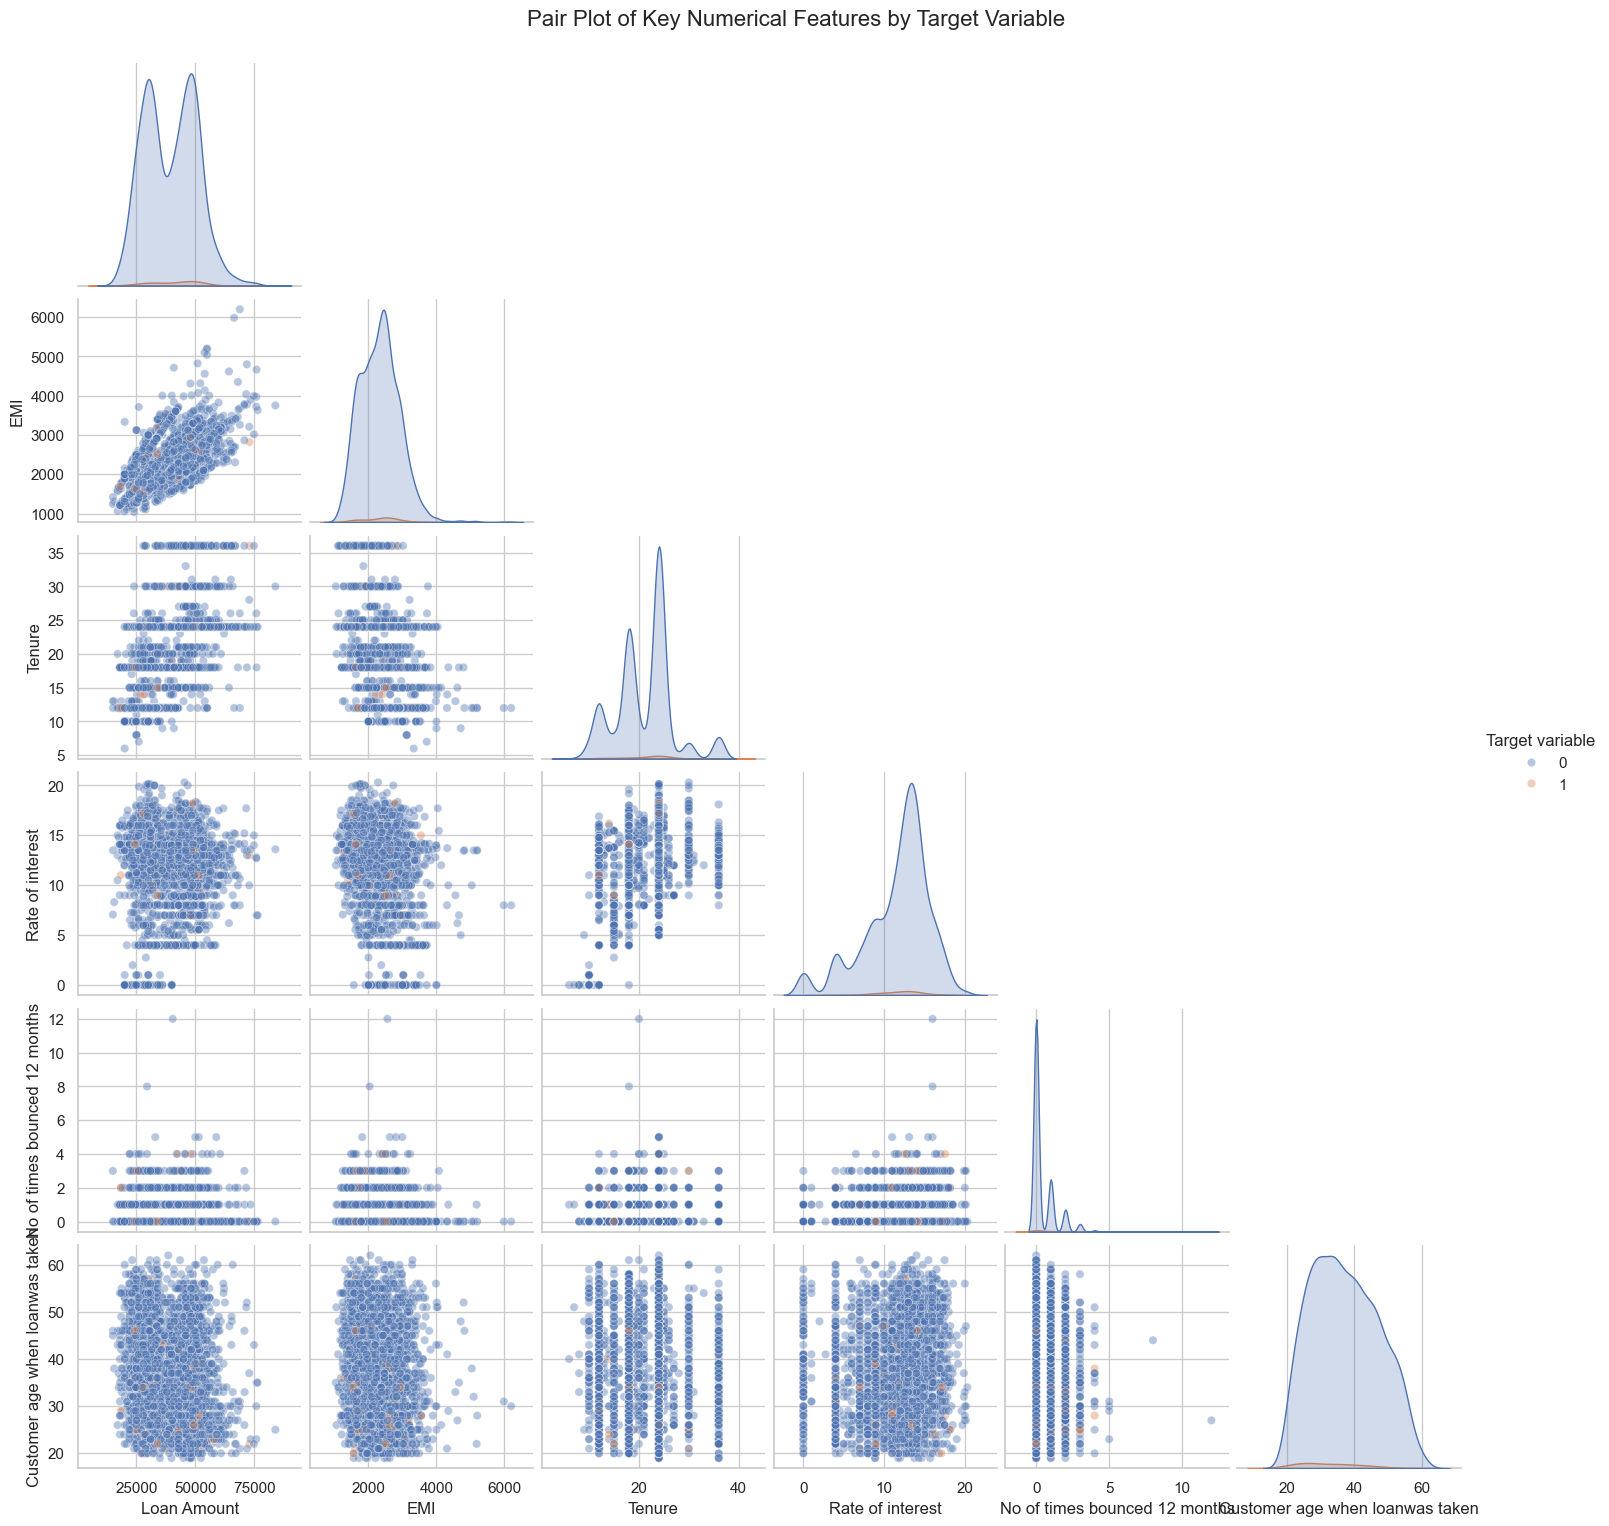

In [30]:
sns.set(style="whitegrid")

sns.pairplot(
    pairplot_data,
    hue='Target variable',
    diag_kind='kde',
    corner=True,
    plot_kws={'alpha': 0.4}
)

plt.suptitle(
    "Pair Plot of Key Numerical Features by Target Variable",
    y=1.02,
    fontsize=16
)
plt.show()

- High linearity exists in features like teanure, number of times bounced,rate of interest.
- Defaulters often show; Higher EMI,More bounce counts and Slightly higher interest rates


<Axes: xlabel='Customer age when loanwas taken', ylabel='Loan Amount'>

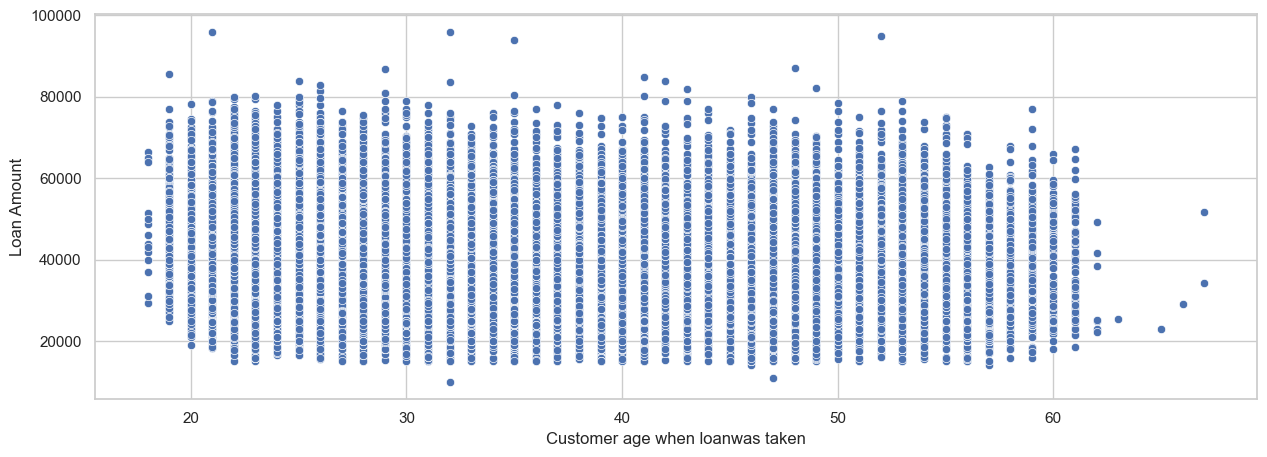

In [31]:
# Explore correlation between age and loan amount
plt.figure(figsize=(15,5))
sns.scatterplot(x=Loan_cleaned['Customer age when loanwas taken'],y='Loan Amount',data=Loan_cleaned)

- There is no clear relationship between age and loan amounts taken and age group is subjected to any loan amount.
- Loans are taken by individuals between 18 and 61 years

## 4. Data Cleaning Cont..

In [32]:
data=Loan_cleaned.copy()

### 4.1 Imputing missing values
To do, investigate them first and document the case for imputation, we might need to drop them.

In [33]:
data.columns = data.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')

In [34]:
CatVariables = data.select_dtypes(include=['object']).columns
NumVariables = data.select_dtypes(include=['float','int']).columns

In [35]:
#create binary for each column that ha missingness
for col in data.columns:
    if data[col].isna().sum() > 0:
        data[col + '_missing'] = data[col].isna().astype(int)

In [36]:
for col in NumVariables:
    data[col].fillna(data[col].median(), inplace=True)

In [ ]:
#MICE imputation
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

iter_imputer = IterativeImputer(random_state=0)
data_imputed = pd.DataFrame(iter_imputer.fit_transform(data[NumVariables]), columns=NumVariables)

In [ ]:
#use imputation with mode on categorical columns
cat_cols = CatVariables 

for col in cat_cols:
    mode_value = data[col].mode()[0] 
    data[col].fillna(mode_value, inplace=True)

### Encoding

In [48]:
# Dealing with categorical columns
# Label Encoding for object to numeric conversion
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

for feature in CatVariables:
    data[feature] = le.fit_transform(data[feature].astype(str))


### Class Imbalance

In [45]:
X=data.drop(['customer_id','target_variable'],axis=1)
y=data[["target_variable"]]

### SMOTE

array([[<Axes: title={'center': 'target_variable'}>]], dtype=object)

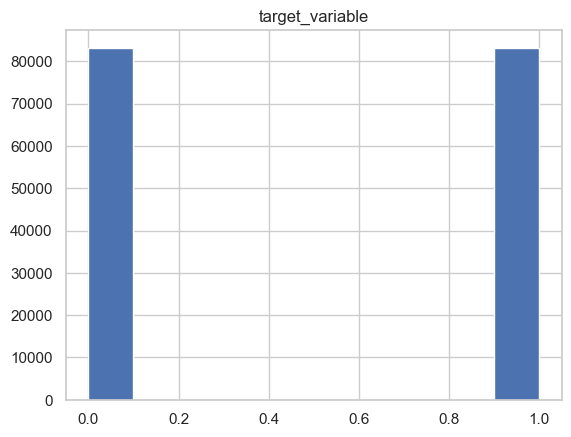

In [49]:
smote_sample=SMOTE(random_state=124,sampling_strategy='auto') # the sampling strategy can be one of float, str, dict or callable `float``,
#it corresponds to the desired ratio of the number of samples in the minority class over the number of samples in the majority class after resampling ie {1:500}
# ``'minority'``: resample only  minority class; 'not minority'``:all but the minority class; ``'not majority'``: all but the majority, ``'all'`` ,``'auto'``:
x_res, y_res=smote_sample.fit_resample(X,y)


# now plot the classes
y_res.hist()

- The model should be able to learn the patterns associated with both defaults and non-defaults. Here we are interested in both an increase in precision and recall.

In [50]:
print(x_res.shape,y_res.shape)

(166388, 28) (166388, 1)


### Explore the linear separabillity of the two classes and document your intuition of the best model type to give you the best results.

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

: 

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Plot
plt.figure(figsize=(8,6))
plt.scatter(X_pca[y==0, 0], X_pca[y==0, 1], alpha=0.5, label='Class 0')
plt.scatter(X_pca[y==1, 0], X_pca[y==1, 1], alpha=0.5, label='Class 1', color='r')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('PCA Projection of Features')
plt.legend()
plt.show()